In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')

In [3]:
print("First 5 rows of the data:")
print(df.head())
print("\nDataset Information:")
df.info()
print("\nCheck for missing values:")
print(df.isnull().sum()) # Good news: this dataset is clean!
print("\nStatistical Summary:")
print(df.describe())

First 5 rows of the data:
   Person ID Gender  Age            Occupation  Sleep Duration  \
0          1   Male   27     Software Engineer             6.1   
1          2   Male   28                Doctor             6.2   
2          3   Male   28                Doctor             6.2   
3          4   Male   28  Sales Representative             5.9   
4          5   Male   28  Sales Representative             5.9   

   Quality of Sleep  Physical Activity Level  Stress Level BMI Category  \
0                 6                       42             6   Overweight   
1                 6                       60             8       Normal   
2                 6                       60             8       Normal   
3                 4                       30             8        Obese   
4                 4                       30             8        Obese   

  Blood Pressure  Heart Rate  Daily Steps Sleep Disorder  
0         126/83          77         4200            NaN  
1       

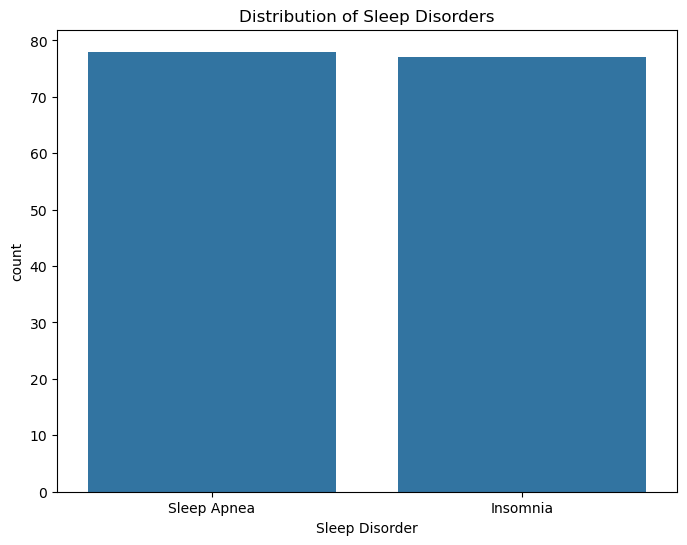

In [4]:
# --- Visualization ---
# 1. How balanced is our target variable?
plt.figure(figsize=(8, 6))
sns.countplot(x='Sleep Disorder', data=df)
plt.title('Distribution of Sleep Disorders')
plt.show()

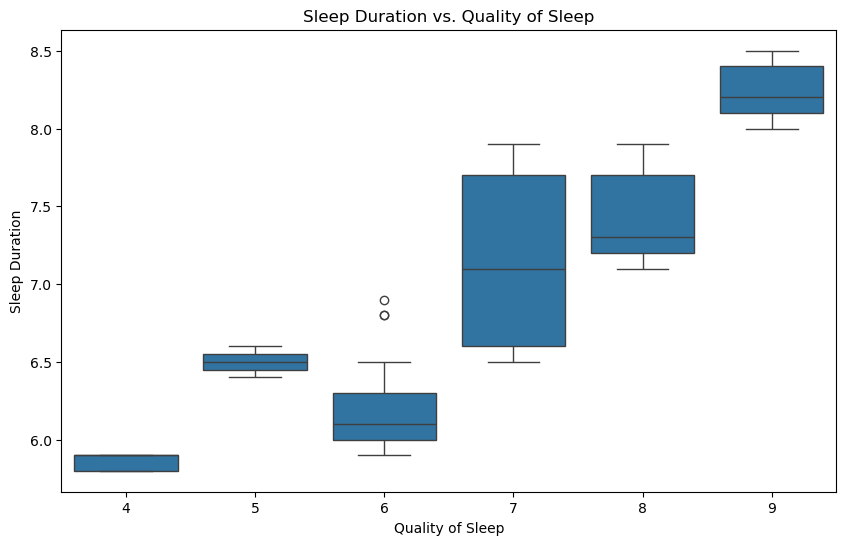

In [5]:
# 2. How does sleep duration affect the quality of sleep?
plt.figure(figsize=(10, 6))
sns.boxplot(x='Quality of Sleep', y='Sleep Duration', data=df)
plt.title('Sleep Duration vs. Quality of Sleep')
plt.show()

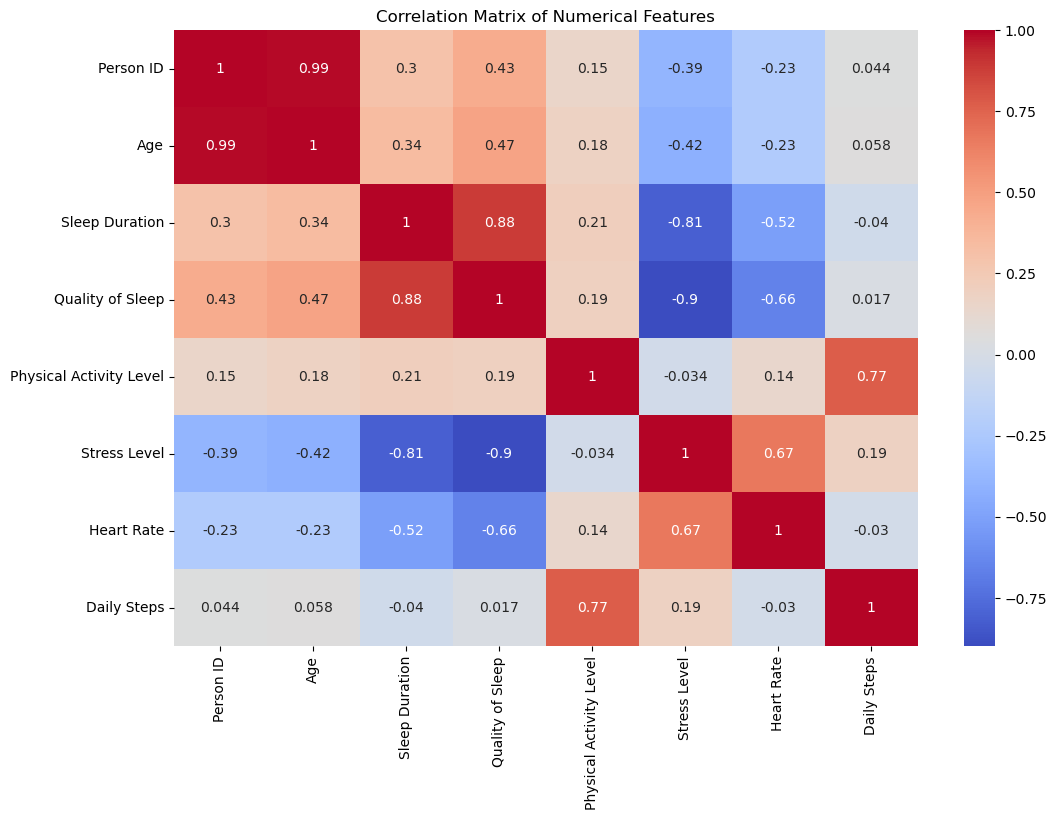

In [6]:
# 3. Correlation between numerical features
# Note: We need to handle non-numeric columns before making a full correlation matrix
numerical_df = df.select_dtypes(include=['float64', 'int64'])
plt.figure(figsize=(12, 8))
sns.heatmap(numerical_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

In [7]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

In [8]:
df = df.drop('Person ID', axis=1)

In [9]:
# --- Handle Categorical Features ---
# Convert columns with text data into numerical data using one-hot encoding
categorical_cols = ['Gender', 'Occupation', 'BMI Category', 'Blood Pressure']
df_processed = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

In [10]:
df_processed['Sleep Disorder'] = df_processed['Sleep Disorder'].astype(str)

In [11]:
# --- Separate Features (X) and Target (y) ---
X = df_processed.drop('Sleep Disorder', axis=1)
y = df_processed['Sleep Disorder']

In [12]:
# --- Encode the Target Variable ---
# Now we can safely encode our string labels into numbers
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

In [13]:
# DEBUGGING STEP: Let's confirm it worked correctly
print("The classes found by the encoder are:", label_encoder.classes_) # This should now print the text labels

The classes found by the encoder are: ['Insomnia' 'Sleep Apnea' 'nan']


In [14]:
# --- Split the Data ---
# Split into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

In [15]:
# --- Scale Numerical Features ---
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [16]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [17]:
# --- Build the ANN Architecture ---
model = keras.Sequential([
    # Input layer: The shape must match the number of features
    layers.Input(shape=(X_train.shape[1],)),
    
    # Hidden Layer 1: 64 neurons, 'relu' is a standard activation function
    layers.Dense(64, activation='relu'),
    
    # Hidden Layer 2: 32 neurons
    layers.Dense(32, activation='relu'),
    
    # Output Layer: 3 neurons (one for each class), 'softmax' for multi-class probability
    layers.Dense(3, activation='softmax')
])

In [18]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,123 (20.01 KB)

 Trainable params: 5,123 (20.01 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy', # Use this loss for integer-encoded labels
    metrics=['accuracy']
)

In [20]:
# --- Train the Model ---
# We'll use 20% of the training data for validation during training
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    validation_split=0.2,
    verbose=1 # This will show the training progress
)

Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 13s 323ms/step - accuracy: 0.2746 - loss: 1.1597 - val_accuracy: 0.5167 - val_loss: 0.8648
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - accuracy: 0.6438 - loss: 0.8346 - val_accuracy: 0.7667 - val_loss: 0.6729
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step - accuracy: 0.8323 - loss: 0.6680 - val_accuracy: 0.9167 - val_loss: 0.5455
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - accuracy: 0.8761 - loss: 0.6126 - val_accuracy: 0.9167 - val_loss: 0.4593
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.8762 - loss: 0.5508 - val_accuracy: 0.9333 - val_loss: 0.4073
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 106ms/step - accuracy: 0.9158 - loss: 0.4149 - val_accuracy: 0.9333 - val_loss: 0.3723
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step - accuracy: 0.8992 - loss: 0.4376 - val_accuracy: 0.9333 - val_loss: 0.3484
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step - accuracy: 0.9289 - loss: 0.3326 - val_accuracy: 0.9333 - val_loss: 0.33

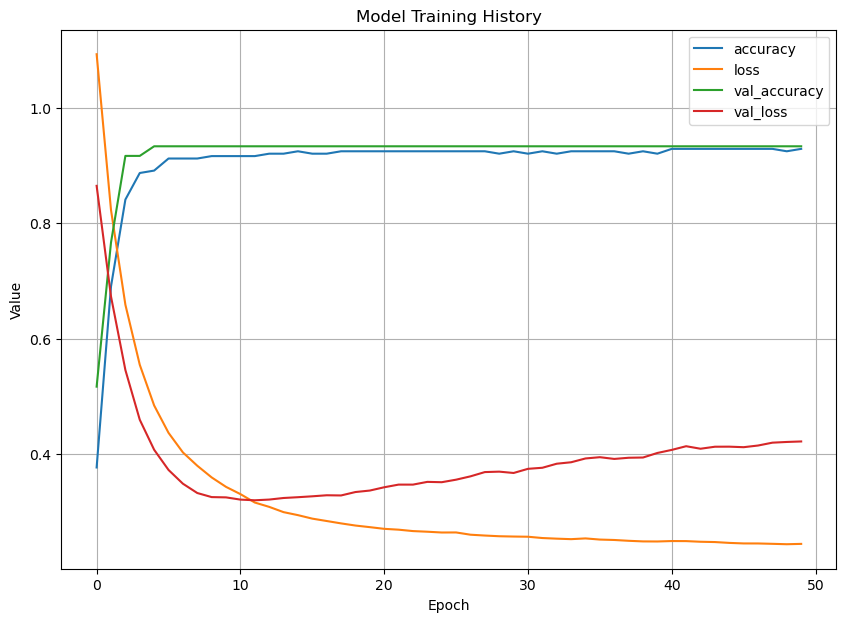

In [21]:
# --- Plot Training History ---
pd.DataFrame(history.history).plot(figsize=(10, 7))
plt.title("Model Training History")
plt.ylabel("Value")
plt.xlabel("Epoch")
plt.grid(True)
plt.show()

In [22]:
# --- Evaluate on the Test Set ---
loss, accuracy = model.evaluate(X_test, y_test)
print(f"\nTest Accuracy: {accuracy*100:.2f}%")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.9248 - loss: 0.3403

Test Accuracy: 92.00%


In [23]:
# --- Make Predictions and Analyze ---
from sklearn.metrics import classification_report, confusion_matrix

y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1) # Convert probabilities to class labels

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 153ms/step


In [24]:
# Print the classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))


Classification Report:
              precision    recall  f1-score   support

    Insomnia       0.87      0.87      0.87        15
 Sleep Apnea       0.88      0.88      0.88        16
         nan       0.95      0.95      0.95        44

    accuracy                           0.92        75
   macro avg       0.90      0.90      0.90        75
weighted avg       0.92      0.92      0.92        75



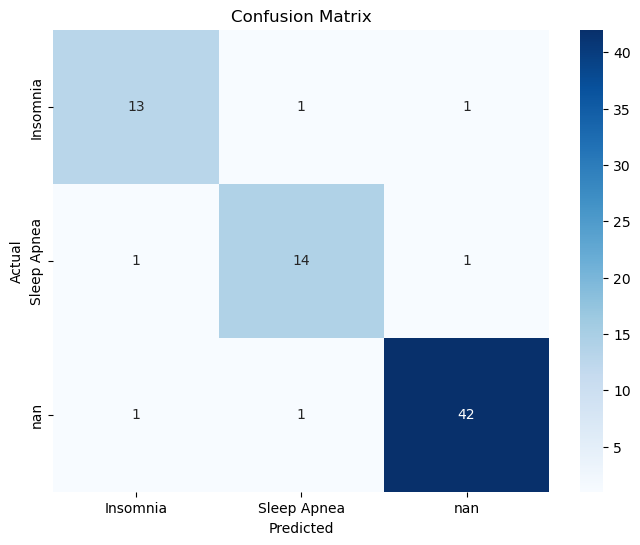

In [25]:
# Display the confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

In [26]:
# --- Step 6: Compile the Model ---
# This configures the model for training.

print("Compiling the model...")
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
print("Model compiled successfully.")

Compiling the model...
Model compiled successfully.


In [27]:
# --- Step 7: Train the Model ---
# This is where the model learns from your data.
# We store the training process in a 'history' object to visualize it later.

print("\nStarting model training...")
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    validation_split=0.2, # Using 20% of training data for validation
    verbose=1 # This will show a progress bar
)
print("Model training completed.")


Starting model training...
Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 293ms/step - accuracy: 0.8803 - loss: 0.3355 - val_accuracy: 0.8833 - val_loss: 0.4441
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step - accuracy: 0.9466 - loss: 0.2146 - val_accuracy: 0.8833 - val_loss: 0.4291
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - accuracy: 0.9134 - loss: 0.2900 - val_accuracy: 0.9333 - val_loss: 0.4308
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.9365 - loss: 0.2200 - val_accuracy: 0.9333 - val_loss: 0.4311
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 104ms/step - accuracy: 0.9245 - loss: 0.2599 - val_accuracy: 0.9333 - val_loss: 0.4374
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.9026 - loss: 0.2968 - val_accuracy: 0.9333 - val_loss: 0.4495
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 104ms/step - accuracy: 0.9334 - loss: 0.2229 - val_accuracy: 0.9333 - val_loss: 0.4515
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.9438 - loss: 0.2100 - val_accur

In [28]:
# Import the necessary libraries for evaluation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

--- Visualizing Model Training History ---


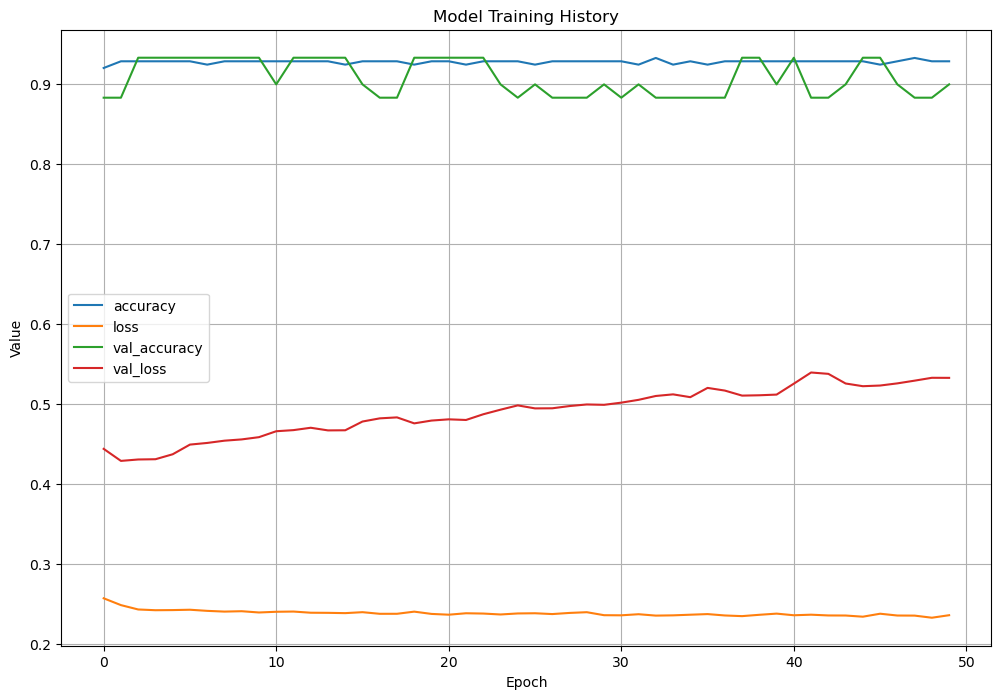

In [29]:
# --- 1. Visualize Training History ---
# The 'history' object you created during training contains the model's performance on each epoch.
# Let's plot the accuracy and loss for both the training and validation sets.

print("--- Visualizing Model Training History ---")
pd.DataFrame(history.history).plot(figsize=(12, 8))
plt.title("Model Training History")
plt.ylabel("Value")
plt.xlabel("Epoch")
plt.grid(True)
plt.show()

In [30]:
# --- 2. Evaluate on the Unseen Test Set ---
# This gives us the final performance metrics on data the model has never seen before.

print("\n--- Evaluating Model on Test Data ---")
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print(f"Test Loss: {loss:.4f}")




--- Evaluating Model on Test Data ---
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.9065 - loss: 0.4241
Test Accuracy: 90.67%
Test Loss: 0.4059


In [31]:
# --- 3. Analyze Detailed Predictions ---
# We want to see more than just the overall accuracy.

# First, get the model's predictions for the test set.
y_pred_probs = model.predict(X_test)
# The output is a probability for each class, so we take the one with the highest probability.
y_pred = np.argmax(y_pred_probs, axis=1)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step


In [32]:
# Now, we can generate a detailed classification report.
# This shows precision, recall, and f1-score for each class.
print("\n--- Classification Report ---")
# We use 'label_encoder.classes_' to show the actual class names instead of numbers
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))


--- Classification Report ---
              precision    recall  f1-score   support

    Insomnia       0.87      0.87      0.87        15
 Sleep Apnea       0.82      0.88      0.85        16
         nan       0.95      0.93      0.94        44

    accuracy                           0.91        75
   macro avg       0.88      0.89      0.89        75
weighted avg       0.91      0.91      0.91        75




--- Confusion Matrix ---


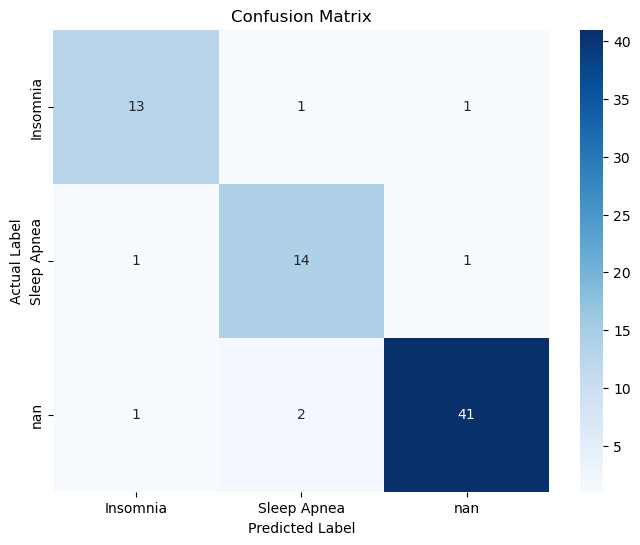

In [33]:

# Finally, let's create a confusion matrix.
# This is the best way to see what mistakes the model is making.
print("\n--- Confusion Matrix ---")
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=label_encoder.classes_, 
            yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

In [34]:
# Example of a model with Dropout
model_tuned = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    
    # Hidden Layer 1
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),  # Add dropout layer here (30% of neurons will be dropped out)
    
    # Hidden Layer 2
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),  # Add another dropout layer here
    
    # Output Layer
    layers.Dense(3, activation='softmax')
])

# You would then compile and train this new model

In [35]:
from tensorflow.keras.callbacks import EarlyStopping

# This will stop training if the validation loss doesn't improve for 5 consecutive epochs
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Now, add this to your model.fit() call
history = model.fit(
    X_train,
    y_train,
    epochs=100, # Set a high number of epochs
    validation_split=0.2,
    callbacks=[early_stopping] # Add the callback here
)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - accuracy: 0.9260 - loss: 0.2446 - val_accuracy: 0.8833 - val_loss: 0.5347
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.9327 - loss: 0.2303 - val_accuracy: 0.8833 - val_loss: 0.5416
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.9358 - loss: 0.2108 - val_accuracy: 0.9000 - val_loss: 0.5327
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - accuracy: 0.9290 - loss: 0.2301 - val_accuracy: 0.9000 - val_loss: 0.5375
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.9367 - loss: 0.2064 - val_accuracy: 0.9000 - val_loss: 0.5383
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9088 - loss: 0.2794 - val_accuracy: 0.9000 - val_loss: 0.5403
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.9209 - loss: 0.2582 - val_accuracy: 0.9000 - val_loss: 0.5417
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.9461 - loss: 0.1994 - val_accuracy: 0.9333 - val_loss:

In [36]:
pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [37]:
import pickle

print("--- Starting to save the assets ---")

# This line CREATES the sleep_model.keras file
model.save('sleep_model.keras')

# These lines CREATE the .pkl files
with open('scaler.pkl', 'wb') as file:
    pickle.dump(scaler, file)

with open('label_encoder.pkl', 'wb') as file:
    pickle.dump(label_encoder, file)

with open('model_columns.pkl', 'wb') as file:
    pickle.dump(X.columns, file)

print("--- Finished saving. The .keras and .pkl files have been created. ---")

--- Starting to save the assets ---
--- Finished saving. The .keras and .pkl files have been created. ---


In [38]:
# --- This code goes in a new cell in your ANN.ipynb notebook ---
print("Training the new REGRESSION model for Sleep Quality...")

# 1. Create the new target variable 'y_reg' (the 1-10 score)
# (Assuming your processed dataframe is 'df_processed')
y_reg = df_processed['Quality of Sleep']

# 2. Split this new target (we use the same train/test split)
# (This assumes you have already run train_test_split and have 'X_train', 'X_test', etc.)
# We need to create the y_train and y_test for this new target.
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X, y_reg, test_size=0.2, random_state=42)

# 3. Scale the input data (X)
# (This assumes your 'scaler' is already fitted)
X_train_scaled_reg = scaler.transform(X_train_reg)
X_test_scaled_reg = scaler.transform(X_test_reg)

# 4. Define the Regression Model architecture
model_reg = keras.Sequential([
    layers.Input(shape=(X_train_scaled_reg.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='linear') # Output 1 number for the score
])

# 5. Compile the model
model_reg.compile(
    optimizer='adam',
    loss='mean_squared_error', # A loss function for regression
    metrics=['mae'] # Mean Absolute Error
)

# 6. Train the model
print("Training the new quality model...")
history_reg = model_reg.fit(
    X_train_scaled_reg,
    y_train_reg,
    epochs=50,
    validation_split=0.2,
    verbose=1
)

# 7. Save the new model
model_reg.save('sleep_quality_model.keras')
print("Successfully trained and saved 'sleep_quality_model.keras'")

Training the new REGRESSION model for Sleep Quality...
Training the new quality model...
Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 8s 274ms/step - loss: 52.2660 - mae: 7.1223 - val_loss: 47.6057 - val_mae: 6.7593
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - loss: 45.9451 - mae: 6.6784 - val_loss: 40.5803 - val_mae: 6.2339
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 105ms/step - loss: 37.9378 - mae: 6.0234 - val_loss: 33.8062 - val_mae: 5.6764
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - loss: 31.7962 - mae: 5.4648 - val_loss: 26.8380 - val_mae: 5.0197
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - loss: 24.3854 - mae: 4.7265 - val_loss: 20.0744 - val_mae: 4.3535
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 114ms/step - loss: 18.2776 - mae: 4.1244 - val_loss: 13.8125 - val_mae: 3.5951
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 128ms/step - loss: 12.4454 - mae: 3.3684 - val_loss: 8.7697 - val_mae: 2.7821
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - loss: 7.2566 - mae: 2.4854 - val_loss